# Анализ эксперимента: новая страница оформления заказа

Анализ строго по `docs/preregistration.md`: один финальный анализ на день 28, основная метрика — конверсия за 7 дней, решение по критерию из раздела 10.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from abtest.stats import (
    srm_test, smd_categorical, diff_proportions, welch_diff, bootstrap_diff,
    ratio_delta, holm, one_sided_harm,
)
from abtest.economics import incremental_profit

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COL = {"control": "#2a78d6", "treatment": "#eb6834"}
NAME = {"control": "контроль", "treatment": "тест"}
WINDOW = pd.Timedelta(days=7)

## 1. Загрузка и таблица на уровне пользователя

Окно метрик — `[assigned_at, assigned_at + 7 дней)`, правая граница не включается. События и заказы агрегируются до пользователя: рандомизировали пользователей, поэтому и единица анализа — пользователь.

In [2]:
a = pd.read_csv("../data/assignments.csv", parse_dates=["assigned_at"])
ev = pd.read_csv("../data/events.csv", parse_dates=["event_time"])
orders = pd.read_csv("../data/orders.csv", parse_dates=["created_at"])

ev = ev.merge(a[["user_id", "assigned_at"]], on="user_id")
orders = orders.merge(a[["user_id", "assigned_at"]], on="user_id")
ev_w = ev[ev.event_time < ev.assigned_at + WINDOW]
ord_w = orders[orders.created_at < orders.assigned_at + WINDOW]


def reached(event_type):
    return a.user_id.isin(ev_w.loc[ev_w.event_type == event_type, "user_id"])


ow = ord_w.groupby("user_id")
lc = ev_w[ev_w.event_type == "view_checkout"].assign(log_ms=lambda d: np.log(d.page_load_ms))

users = a.assign(
    cart=reached("add_to_cart"),
    checkout=reached("view_checkout"),
    pay=reached("payment_start"),
    n_orders=a.user_id.map(ow.size()).fillna(0),
    revenue=a.user_id.map(ow.revenue.sum()).fillna(0),
    n_refunds=a.user_id.map(ow.refunded.sum()).fillna(0),
    log_load=a.user_id.map(lc.groupby("user_id").log_ms.mean()),
    load_ms=a.user_id.map(lc.groupby("user_id").page_load_ms.median()),
)
users["buy"] = users.n_orders > 0
c, t = users[users.variant == "control"], users[users.variant == "treatment"]
users.head()

,user_id,variant,assigned_at,platform,country,source,cart,checkout,pay,n_orders,revenue,n_refunds,log_load,load_ms,buy
0,1,treatment,2026-03-02 00:00:27,ios,RU,organic,False,False,False,0.0000,0.0000,0.0000,NaN,NaN,False
1,2,control,2026-03-02 00:00:44,web,RU,organic,True,False,False,0.0000,0.0000,0.0000,NaN,NaN,False
2,3,treatment,2026-03-02 00:00:49,ios,RU,email,False,False,False,0.0000,0.0000,0.0000,NaN,NaN,False
3,4,control,2026-03-02 00:00:55,android,RU,paid,True,True,False,0.0000,0.0000,0.0000,7.9381,2802.0000,False
4,5,control,2026-03-02 00:01:11,ios,RU,organic,True,False,False,0.0000,0.0000,0.0000,NaN,NaN,False


In [3]:
users.groupby("variant")[["cart", "checkout", "pay", "buy", "revenue", "n_orders"]].agg(["sum", "mean"])

cart        checkout          pay          buy         \
             sum   mean      sum   mean   sum   mean   sum   mean   
variant                                                             
control    18799 0.2990    12586 0.2002  8041 0.1279  6186 0.0984   
treatment  18996 0.3009    12679 0.2008  8730 0.1383  6789 0.1075   

                revenue           n_orders         
                    sum     mean       sum   mean  
variant                                            
control   15760391.0000 250.7101 6186.0000 0.0984  
treatment 15536898.0000 246.0823 6789.0000 0.1075

## 2. Проверки до анализа

SRM: хи-квадрат против 50/50, порог остановки p < 0.001. Баланс ковариат, известных до назначения: стандартизованная разница долей по каждой категории должна быть меньше 0.1.

In [4]:
srm = srm_test(len(c), len(t))
print(f"пользователей: контроль {len(c):,}, тест {len(t):,}")
print(f"хи-квадрат = {srm.chi2:.3f}, p = {srm.p_value:.3f}, SRM: {'да' if srm.srm else 'нет'}")

пользователей: контроль 62,863, тест 63,137
хи-квадрат = 0.596, p = 0.440, SRM: нет


In [5]:
smd = pd.concat(
    {col: smd_categorical(users, col, "variant").by_category for col in ["platform", "country", "source"]}
).rename("smd").to_frame()
smd["превышен порог 0.1"] = smd.smd.abs() >= 0.1
print(f"max |SMD| = {smd.smd.abs().max():.4f}")
smd

max |SMD| = 0.0085


smd  превышен порог 0.1
platform android   0.0010               False
         ios      -0.0011               False
         web       0.0002               False
country  AM        0.0085               False
         BY        0.0027               False
         KZ       -0.0047               False
         RU       -0.0046               False
         UZ        0.0026               False
source   email    -0.0048               False
         organic  -0.0025               False
         paid      0.0073               False
         referral -0.0018               False

## 3. Основная метрика: конверсия за 7 дней

z-тест разницы долей, 95% CI Вальда для абсолютной разницы и CI дельта-методом для относительной.

In [6]:
conv = diff_proportions(c.buy.sum(), len(c), t.buy.sum(), len(t))
print(f"конверсия: контроль {conv.p_c:.2%}, тест {conv.p_t:.2%}")
print(f"разница: {conv.diff * 100:+.2f} п.п., 95% CI [{conv.ci_low * 100:+.2f}; {conv.ci_high * 100:+.2f}] п.п.")
print(f"относительно: {conv.rel:+.1%}, 95% CI [{conv.rel_ci_low:+.1%}; {conv.rel_ci_high:+.1%}]")
print(f"z = {conv.z:.2f}, p = {conv.p_value:.2g}")

конверсия: контроль 9.84%, тест 10.75%
разница: +0.91 п.п., 95% CI [+0.58; +1.25] п.п.
относительно: +9.3%, 95% CI [+5.7%; +12.8%]
z = 5.33, p = 9.9e-08


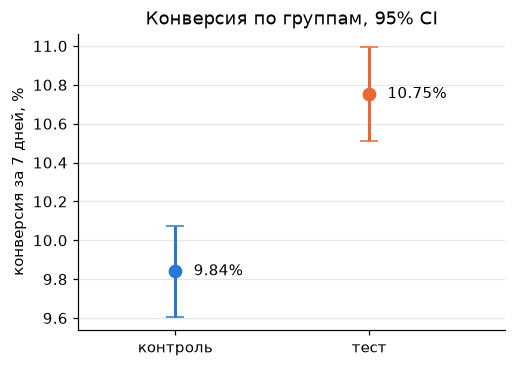

In [7]:
q = 1.96
fig, ax = plt.subplots(figsize=(5, 3.5))
for i, (g, p, n) in enumerate([("control", conv.p_c, len(c)), ("treatment", conv.p_t, len(t))]):
    h = q * np.sqrt(p * (1 - p) / n)
    ax.errorbar(i, p * 100, yerr=h * 100, fmt="o", color=COL[g], ms=8, lw=2, capsize=6)
    ax.annotate(f"{p:.2%}", (i, p * 100), xytext=(12, 0), textcoords="offset points", va="center")
ax.set_xticks([0, 1], [NAME["control"], NAME["treatment"]])
ax.set_xlim(-0.5, 1.7)
ax.set_ylabel("конверсия за 7 дней, %")
ax.set_title("Конверсия по группам, 95% CI")
ax.grid(axis="y", alpha=0.3)
plt.show()

## 4. Вторичные метрики с поправкой Холма

ARPU — Уэлч, бутстреп по пользователям для сверки. Средний чек — ratio-метрика (выручка / заказы у покупателей) с дельта-методом; сравнение не рандомизировано, потому что состав покупателей зависит от варианта. Поправка Холма по четырём метрикам, FWER 0.05.

In [8]:
arpu = welch_diff(c.revenue, t.revenue)
arpu_boot = bootstrap_diff(c.revenue, t.revenue)
print(f"ARPU: контроль {c.revenue.mean():.2f} ₽, тест {t.revenue.mean():.2f} ₽")
print(f"Уэлч:    {arpu.diff:+.2f} ₽, 95% CI [{arpu.ci_low:+.2f}; {arpu.ci_high:+.2f}], p = {arpu.p_value:.3f}")
print(f"бутстреп: {arpu_boot.diff:+.2f} ₽, 95% CI [{arpu_boot.ci_low:+.2f}; {arpu_boot.ci_high:+.2f}], se = {arpu_boot.se:.2f} (Уэлч se = {arpu.se:.2f})")

ARPU: контроль 250.71 ₽, тест 246.08 ₽
Уэлч:    -4.63 ₽, 95% CI [-16.31; +7.05], p = 0.438
бутстреп: -4.63 ₽, 95% CI [-16.32; +6.92], se = 5.94 (Уэлч se = 5.96)


In [9]:
bc, bt = c[c.buy], t[t.buy]
aov = ratio_delta(bc.revenue, bc.n_orders, bt.revenue, bt.n_orders)
cart = diff_proportions(c.cart.sum(), len(c), t.cart.sum(), len(t))
pay = diff_proportions(c.pay.sum(), len(c), t.pay.sum(), len(t))

sec = pd.DataFrame([
    ("ARPU, ₽", c.revenue.mean(), t.revenue.mean(), arpu.diff, arpu.ci_low, arpu.ci_high, arpu.p_value),
    ("средний чек, ₽", aov.ratio_c, aov.ratio_t, aov.diff, aov.ci_low, aov.ci_high, aov.p_value),
    ("доля корзины, п.п.", cart.p_c * 100, cart.p_t * 100, cart.diff * 100, cart.ci_low * 100, cart.ci_high * 100, cart.p_value),
    ("доля оплаты, п.п.", pay.p_c * 100, pay.p_t * 100, pay.diff * 100, pay.ci_low * 100, pay.ci_high * 100, pay.p_value),
], columns=["метрика", "контроль", "тест", "эффект", "CI low", "CI high", "p"]).set_index("метрика")
h = holm(sec.p)
sec["p Холм"] = h.p_adj
sec["решение"] = np.where(h.reject, "значимо", "не значимо")
print(f"средний чек: {aov.diff / aov.ratio_c:+.1%} к контролю")
sec

средний чек: -10.2% к контролю


,контроль,тест,эффект,CI low,CI high,p,p Холм,решение
метрика,,,,,,,,
"ARPU, ₽",250.7101,246.0823,-4.6278,-16.3105,7.0548,0.4375,0.8750,не значимо
"средний чек, ₽",2547.7515,2288.5400,-259.2115,-341.4231,-177.0000,0.0000,0.0000,значимо
"доля корзины, п.п.",29.9047,30.0870,0.1822,-0.3238,0.6883,0.4803,0.8750,не значимо
"доля оплаты, п.п.",12.7913,13.8271,1.0358,0.6607,1.4108,0.0000,0.0000,значимо


## 5. Guardrail-метрики

Доля возвратов — заказы с возвратом / заказы в окне, односторонний тест на рост. Время загрузки: у пользователя 1–2 показа страницы оформления, поэтому p50/p95 внутри пользователя вырождены; берём среднее log(page_load_ms) по пользователю и Уэлча, односторонне на рост. p50 и p95 распределения по пользователям — описательно.

In [10]:
ref = diff_proportions(c.n_refunds.sum(), c.n_orders.sum(), t.n_refunds.sum(), t.n_orders.sum())
ref_harm = one_sided_harm(ref.diff, ref.se, worse="higher")
print(f"доля возвратов: контроль {ref.p_c:.2%}, тест {ref.p_t:.2%}, разница {ref.diff * 100:+.2f} п.п.")
print(f"односторонний z = {ref_harm.z:.2f}, p = {ref_harm.p_value:.3f}, ухудшение: {'да' if ref_harm.harm else 'нет'}")

доля возвратов: контроль 4.67%, тест 5.11%, разница +0.44 п.п.
односторонний z = 1.16, p = 0.123, ухудшение: нет


In [11]:
lc_c, lc_t = c.log_load.dropna(), t.log_load.dropna()
load = welch_diff(lc_c, lc_t)
load_harm = one_sided_harm(load.diff, load.se, worse="higher")
print(f"пользователей с замером: контроль {len(lc_c):,}, тест {len(lc_t):,}")
print(f"разница среднего log: {load.diff:+.4f} (≈ {np.expm1(load.diff):+.2%} к геометрическому среднему)")
print(f"односторонний z = {load_harm.z:.2f}, p = {load_harm.p_value:.3f}, ухудшение: {'да' if load_harm.harm else 'нет'}")
users.groupby("variant").load_ms.quantile([0.5, 0.95]).unstack().rename(columns={0.5: "p50, мс", 0.95: "p95, мс"})

пользователей с замером: контроль 12,586, тест 12,679
разница среднего log: +0.0023 (≈ +0.23% к геометрическому среднему)
односторонний z = 0.41, p = 0.342, ухудшение: нет


,"p50, мс","p95, мс"
variant,,
control,1796.0000,3766.0000
treatment,1807.0000,3766.6000


## 6. Экономика

Годовая прибыль = прирост ARPU × 6000 × 365 пользователей × маржа 0.3 − 6 млн ₽ (внедрение + поддержка за год). Безубыточный прирост ARPU — тот, при котором прибыль равна нулю.

In [12]:
YEAR_USERS, MARGIN, COST = 6000 * 365, 0.3, 6_000_000
prof = incremental_profit(arpu.diff, (arpu.ci_low, arpu.ci_high), YEAR_USERS, MARGIN, COST)
print(f"безубыточный прирост ARPU: {prof.breakeven_arpu:.2f} ₽")
print(f"прирост ARPU: {arpu.diff:+.2f} ₽, 95% CI [{arpu.ci_low:+.2f}; {arpu.ci_high:+.2f}]")
print(f"годовая прибыль: {prof.profit / 1e6:+.2f} млн ₽, 95% CI [{prof.profit_low / 1e6:+.2f}; {prof.profit_high / 1e6:+.2f}] млн ₽")
print(f"выше безубыточности: {'да' if prof.above_breakeven else 'нет'}")

безубыточный прирост ARPU: 9.13 ₽
прирост ARPU: -4.63 ₽, 95% CI [-16.31; +7.05]
годовая прибыль: -9.04 млн ₽, 95% CI [-16.72; -1.36] млн ₽
выше безубыточности: нет


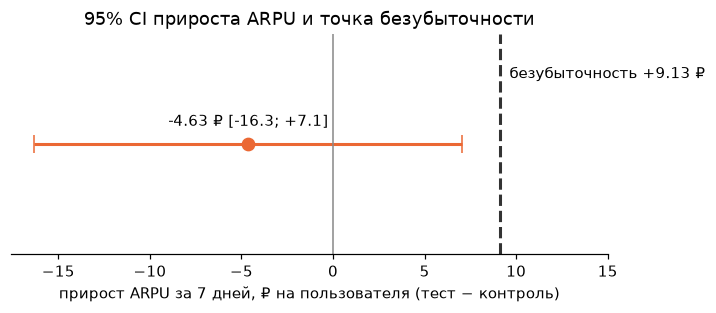

In [13]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.errorbar(arpu.diff, 0, xerr=[[arpu.diff - arpu.ci_low], [arpu.ci_high - arpu.diff]],
            fmt="o", color=COL["treatment"], ms=8, lw=2, capsize=6)
ax.axvline(0, color="#888", lw=1)
ax.axvline(prof.breakeven_arpu, color="#333", lw=2, ls="--")
ax.annotate(f"безубыточность +{prof.breakeven_arpu:.2f} ₽", (prof.breakeven_arpu, 0.6),
            xytext=(6, 0), textcoords="offset points", ha="left")
ax.set_xlim(right=15)
ax.annotate(f"{arpu.diff:+.2f} ₽ [{arpu.ci_low:+.1f}; {arpu.ci_high:+.1f}]", (arpu.diff, 0),
            xytext=(0, 12), textcoords="offset points", ha="center")
ax.set_ylim(-1, 1)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel("прирост ARPU за 7 дней, ₽ на пользователя (тест − контроль)")
ax.set_title("95% CI прироста ARPU и точка безубыточности")
plt.show()

## 7. Почему конверсия растёт, а выручка нет

ARPU = конверсия × выручка на покупателя. Изменение раскладывается точно на два вклада: Δконверсии × средний чек (в среднем по группам) и Δчека × конверсия (в среднем по группам).

In [14]:
rpb_c, rpb_t = bc.revenue.mean(), bt.revenue.mean()
d_conv, d_rpb = conv.p_t - conv.p_c, rpb_t - rpb_c
dec = pd.DataFrame({
    "вклад, ₽": [d_conv * (rpb_c + rpb_t) / 2, d_rpb * (conv.p_c + conv.p_t) / 2],
    "log-вклад": [np.log(conv.p_t / conv.p_c), np.log(rpb_t / rpb_c)],
}, index=["конверсия", "выручка на покупателя"])
dec.loc["итого ARPU"] = dec.sum()
print(f"ARPU: {c.revenue.mean():.2f} → {t.revenue.mean():.2f} ₽ ({arpu.diff:+.2f} ₽, log {np.log(t.revenue.mean() / c.revenue.mean()):+.4f})")
dec

ARPU: 250.71 → 246.08 ₽ (-4.63 ₽, log -0.0186)


,"вклад, ₽",log-вклад
конверсия,22.0622,0.0887
выручка на покупателя,-26.6900,-0.1073
итого ARPU,-4.6278,-0.0186


Рост конверсии на ~9% почти целиком съеден падением выручки на покупателя на ~10%: новая страница добирает покупателей с меньшими чеками и/или снижает чек. Какой из механизмов работает, по этим данным не различить — средний чек сравнивается между нерандомизированными подвыборками.

## 8. Анализ среди дошедших до страницы оформления

Срез по view_checkout в окне убирает пользователей, которых изменение не могло затронуть, и снижает шум. Он корректен, только если доля дошедших не зависит от варианта: иначе группы внутри среза несравнимы. Это не замена основному анализу — срез обусловлен событием после назначения, а решение принимается по всем назначенным.

In [15]:
reach = diff_proportions(c.checkout.sum(), len(c), t.checkout.sum(), len(t))
print(f"дошли до оформления: контроль {reach.p_c:.2%}, тест {reach.p_t:.2%}, "
      f"разница {reach.diff * 100:+.2f} п.п. [{reach.ci_low * 100:+.2f}; {reach.ci_high * 100:+.2f}], p = {reach.p_value:.3f}")
print(f"покупки без view_checkout в окне: {(users.buy & ~users.checkout).sum()}")

cc, tc = c[c.checkout], t[t.checkout]
conv_ck = diff_proportions(cc.buy.sum(), len(cc), tc.buy.sum(), len(tc))
print(f"конверсия среди дошедших: контроль {conv_ck.p_c:.2%}, тест {conv_ck.p_t:.2%}")
print(f"разница {conv_ck.diff * 100:+.2f} п.п., 95% CI [{conv_ck.ci_low * 100:+.2f}; {conv_ck.ci_high * 100:+.2f}], "
      f"относительно {conv_ck.rel:+.1%}, p = {conv_ck.p_value:.2g}")

дошли до оформления: контроль 20.02%, тест 20.08%, разница +0.06 п.п. [-0.38; +0.50], p = 0.789
покупки без view_checkout в окне: 0
конверсия среди дошедших: контроль 49.15%, тест 53.55%
разница +4.40 п.п., 95% CI [+3.16; +5.63], относительно +8.9%, p = 2.8e-12


## 9. Подглядывание

Для каждого дня — z-тест конверсии по данным на конец дня: пользователи, назначенные до конца дня, покупки до конца дня внутри их 7-дневного окна. График показывает, как менялся бы вывод при ежедневных просмотрах; по предрегистрации решение принимается только на день 28 (2026-03-29).

In [16]:
days = pd.date_range("2026-03-03", "2026-03-29")
buy_time = a.user_id.map(ord_w.groupby("user_id").created_at.min())
rows = []
for d in days:
    end = d + pd.Timedelta(days=1)
    m = a.assigned_at < end
    b = buy_time[m] < end
    g = a.loc[m, "variant"]
    r = diff_proportions(b[g == "control"].sum(), (g == "control").sum(), b[g == "treatment"].sum(), (g == "treatment").sum())
    rows.append((d, (d - pd.Timestamp("2026-03-02")).days + 1, m.sum(), r.diff * 100, r.p_value))
peek = pd.DataFrame(rows, columns=["дата", "день", "пользователей", "разница, п.п.", "p"]).set_index("дата")
print(f"дней с p < 0.05: {(peek.p < 0.05).sum()} из {len(peek)}; первый: {peek.index[peek.p < 0.05].min():%Y-%m-%d}")
print(f"день 28 совпадает с основным анализом: {np.isclose(peek.p.iloc[-1], conv.p_value)}")
peek

дней с p < 0.05: 22 из 27; первый: 2026-03-05
день 28 совпадает с основным анализом: True


,день,пользователей,"разница, п.п.",p
дата,,,,
2026-03-03,2,12000,0.4726,0.0569
2026-03-04,3,18000,0.3658,0.0948
2026-03-05,4,24000,0.4860,0.0153
2026-03-06,5,30000,0.4597,0.0192
2026-03-07,6,36000,0.2887,0.1440
2026-03-08,7,42000,0.3542,0.0811
2026-03-09,8,48000,0.3621,0.0726
2026-03-10,9,54000,0.4682,0.0194
2026-03-11,10,60000,0.4060,0.0388


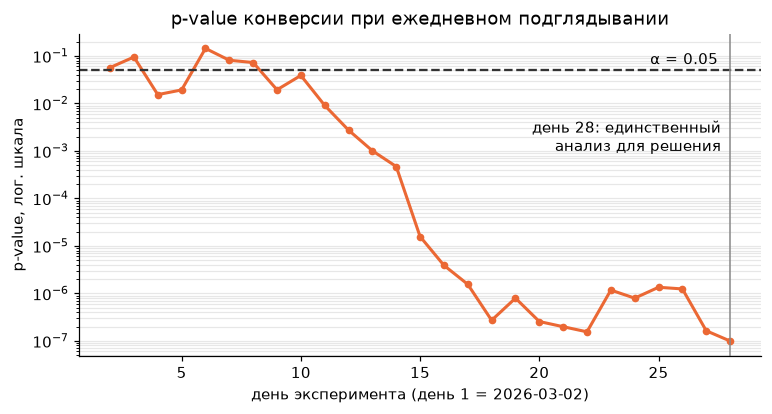

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(peek.день, peek.p, color=COL["treatment"], lw=2, marker="o", ms=4)
ax.axhline(0.05, color="#333", lw=1.5, ls="--")
ax.annotate("α = 0.05", (27.5, 0.05), xytext=(0, 4), textcoords="offset points", ha="right")
ax.axvline(28, color="#888", lw=1)
ax.annotate("день 28: единственный\nанализ для решения", (28, 1e-3), xytext=(-6, 0),
            textcoords="offset points", ha="right")
ax.set_yscale("log")
ax.set_xlabel("день эксперимента (день 1 = 2026-03-02)")
ax.set_ylabel("p-value, лог. шкала")
ax.set_title("p-value конверсии при ежедневном подглядывании")
ax.grid(axis="y", alpha=0.3, which="both")
plt.show()

## 10. Решение по критерию предрегистрации

Внедряем, только если выполнены все три условия критерия из docs/preregistration.md.

In [18]:
crit = pd.DataFrame([
    ("основная метрика значимо выросла (p < 0.05)", f"{conv.diff * 100:+.2f} п.п., p = {conv.p_value:.1g}", conv.p_value < 0.05 and conv.diff > 0),
    ("точечный прирост ARPU > безубыточности", f"{arpu.diff:+.2f} ₽ vs {prof.breakeven_arpu:.2f} ₽", prof.above_breakeven),
    ("guardrail не ухудшились", f"возвраты p = {ref_harm.p_value:.3f}, загрузка p = {load_harm.p_value:.3f}", not (ref_harm.harm or load_harm.harm)),
], columns=["условие", "факт", "выполнено"]).set_index("условие")
ok = crit.выполнено.all()
print("итог:", "внедрять" if ok else "не внедрять")
crit

итог: не внедрять


,факт,выполнено
условие,,
основная метрика значимо выросла (p < 0.05),"+0.91 п.п., p = 1e-07",True
точечный прирост ARPU > безубыточности,-4.63 ₽ vs 9.13 ₽,False
guardrail не ухудшились,"возвраты p = 0.123, загрузка p = 0.342",True


Конверсия значимо выросла, guardrail-метрики не ухудшились, но ARPU не вырос: точечная оценка отрицательная, а верхняя граница CI ниже безубыточных 9.13 ₽. Годовая прибыль от внедрения отрицательна по всему интервалу, поэтому новую страницу не внедряем. Продлевать этот тест нельзя; если версию дорабатывать (удержать средний чек), то в новом эксперименте с новой предрегистрацией.